# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Peng 2019's PDAC malignant manifold is **non-branching**: one connected, low-aspect body with no
discrete arms. The correct topology is therefore a **principal curve** (ElPiGraph, non-branching by
construction) fit on the *joint* Harmony embedding — **not** a re-embedding (re-embedding an
anisotropic compartment fabricates folds). The three embryonic signatures were scored in 01 and are
re-scored here canonically against the shared **union** pool and graph-smoothed for geography. The
curve is rooted at the Gast/pSom-high developmental origin (neural crest is developmentally *late*);
pseudotime then flows outward. This pseudotime axis is used in 03 to test **whether the embryonic
module pattern maps onto it** (Gate 2). Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and re-score developmental modules
Keep all cells on their original joint embedding coordinates — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union**
control pool and graph-smoothed (knn-connectivity averaging) to read geography rather than 10x
per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
s = np.linalg.svd(cc, full_matrices=False)[1]
print(f'UMAP principal-axis ratio (major/minor): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 7945 cells on the joint embedding
UMAP principal-axis ratio (major/minor): 1.17
Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 100/104 genes present
raw module means (honest readout): {'Gast': -0.047, 'pSom': 0.0975, 'Crest': -0.0546}


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation, keeping the arc
smooth. 0 forks confirms a non-branching topology (a `curve`, not a `tree`).

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.79 (>1 = fold-free)


### Derive the root (developmental order, data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Neural crest is developmentally *late*, so the root is never placed at the Crest tip (the Kürten
root error). Pseudotime then flows from that origin.

In [5]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0434 pSom=+0.0900 Crest=-0.0496
tip 2: Gast=-0.0542 pSom=+0.0897 Crest=-0.0478
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.378 p=6.8e-268
  pSom_sm: rho=+0.105 p=5.4e-21
  Crest_sm: rho=-0.103 p=4.5e-20
Neural-crest-high decile mean pseudotime = 0.60
Somitogenesis-high decile mean pseudotime = 0.55
Gastrulation-high decile mean pseudotime = 0.13


### House orientation (re-used from 01, verified against pseudotime)
The house orientation was derived **once in 01** (rotation to horizontal; pSom-high origin on the
left) and stored as `X_umap_lin`. Every UMAP across 01–04 re-uses these exact coordinates. Here we
**verify** the layout now that pseudotime exists: the correlation of the stored `X_umap_lin` x-axis
with pseudotime should be strongly positive (origin on the left).

In [6]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (positive -> origin on the left, layout consistent)')
assert abs(r) > 0.5, 'stored orientation not pseudotime-consistent'

corr(x_lin, pseudotime) = +0.91 (positive -> origin on the left, layout consistent)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


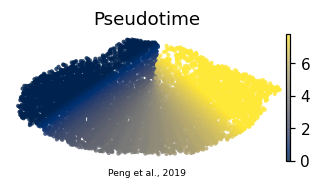

In [7]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')